# Road Accident Severity Prediction - ML notebook
Steps follow sir's guide: load data, clean, explore, build features, compare 3 models, tune, evaluate, save for the FastAPI app.
Only classical machine learning is used (no deep learning).

**Run top to bottom.** Keep `US_Accidents_50000.csv` and `features.py` in the same folder as this notebook.

## Step 1 - Load the data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import joblib
import features as F          # our own cleaning + feature code (also used by main.py)

raw = pd.read_csv("US_Accidents_50000.csv")
print("Rows, columns:", raw.shape)
print("\nSeverity counts:")
print(raw["Severity"].value_counts().sort_index())

Rows, columns: (49998, 46)

Severity counts:
Severity
1      435
2    39833
3     8406
4     1324
Name: count, dtype: int64


**What this shows:** the data is *not* balanced. Severity 2 is about 80% of the rows, Severity 1 is under 1%. This is why we later give rare classes more weight and judge models with macro-F1, not plain accuracy.

## Step 2 - Missing values and cleaning

In [2]:
miss = (raw.isnull().mean() * 100).round(1)
print("Columns with missing values (%):")
print(miss[miss > 0].sort_values(ascending=False))

X = F.clean(raw)          # keeps 15 useful columns, blank precipitation = 0
y = raw["Severity"]
print("\nShape after cleaning:", X.shape)
print(X.head(3).to_string())

Columns with missing values (%):
End_Lat                  44.2
End_Lng                  44.2
Precipitation(in)        28.8
Wind_Chill(F)            26.1
Wind_Speed(mph)           7.4
Visibility(mi)            2.3
Humidity(%)               2.3
Weather_Condition         2.2
Wind_Direction            2.2
Temperature(F)            2.1
Pressure(in)              1.8
Weather_Timestamp         1.5
Nautical_Twilight         0.3
Sunrise_Sunset            0.3
Airport_Code              0.3
Astronomical_Twilight     0.3
Civil_Twilight            0.3
Street                    0.2
Timezone                  0.1
dtype: float64

Shape after cleaning: (49998, 15)
   Hour  DayOfWeek  Temperature(F)  Humidity(%)  Visibility(mi)  Wind_Speed(mph)  Precipitation(in)  Junction  Traffic_Signal  Crossing  Stop  Railway  Is_Night Weather_Condition State
0    16          6            73.9         48.0            10.0              NaN                0.0         0               0         0     0        0         0  

**Choices made:** End_Lat/End_Lng (44% blank) and Wind_Chill (26% blank) are not used. Blank precipitation means no rain was recorded, so it becomes 0. Other numeric blanks are filled with the training-set median (Step 5). `Distance(mi)` and `Source` are not used because they are only known after the accident or reflect how the record was collected.

## Step 3 - Exploratory analysis (EDA)

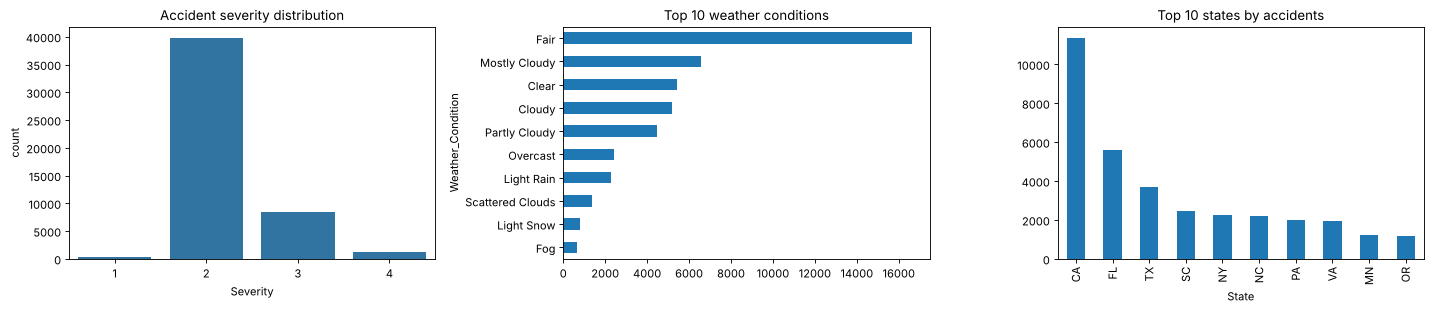

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
sns.countplot(x="Severity", data=raw, ax=ax[0]); ax[0].set_title("Accident severity distribution")
raw["Weather_Condition"].value_counts().head(10).plot.barh(ax=ax[1], title="Top 10 weather conditions").invert_yaxis()
raw["State"].value_counts().head(10).plot.bar(ax=ax[2], title="Top 10 states by accidents")
plt.tight_layout(); plt.show()

Accidents by timezone:
Timezone
US/Eastern     23121
US/Pacific     13486
US/Central     10558
US/Mountain     2781
Unknown           52
Name: count, dtype: int64


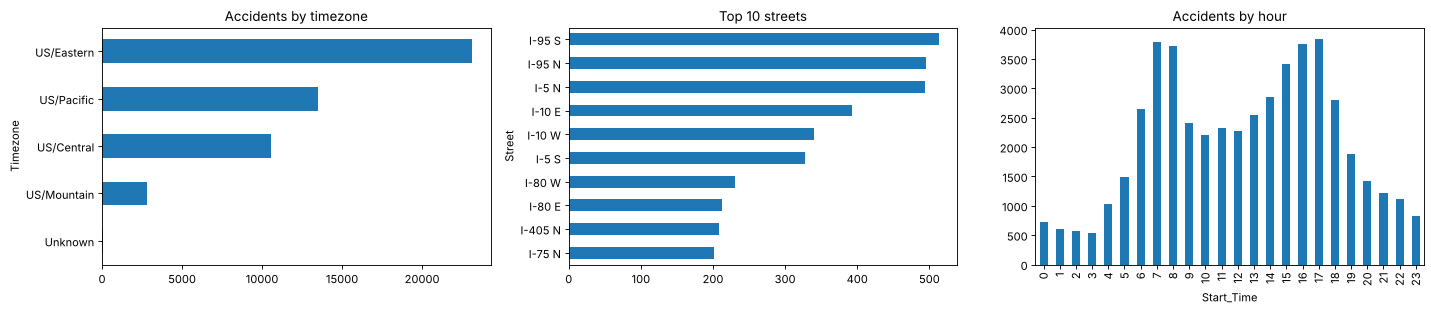

In [4]:
tz = raw["Timezone"].fillna("Unknown").value_counts()
print("Accidents by timezone:"); print(tz)

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
tz.plot.barh(ax=ax[0], title="Accidents by timezone").invert_yaxis()
raw["Street"].value_counts().head(10).plot.barh(ax=ax[1], title="Top 10 streets").invert_yaxis()
pd.to_datetime(raw["Start_Time"], format="mixed").dt.hour.value_counts().sort_index().plot.bar(ax=ax[2], title="Accidents by hour")
plt.tight_layout(); plt.show()

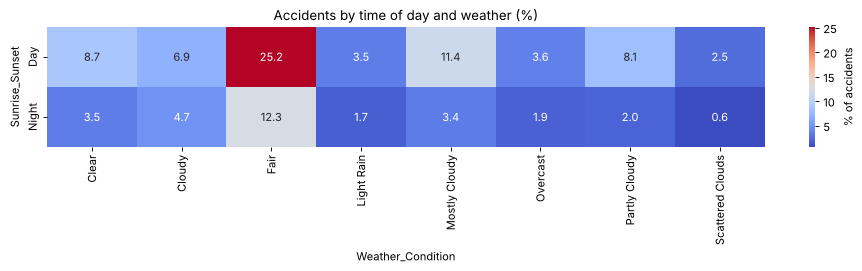

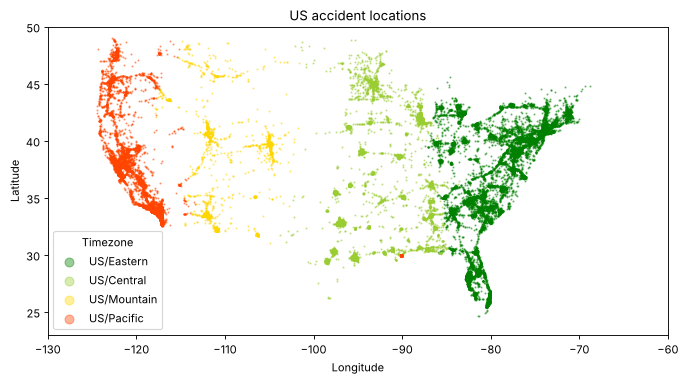

In [5]:
# time of day x weather (percentage of all accidents) - from the analysis notebook
d = raw.dropna(subset=["Sunrise_Sunset", "Weather_Condition"])
top8 = d["Weather_Condition"].value_counts().head(8).index
tab = pd.crosstab(d["Sunrise_Sunset"], d[d["Weather_Condition"].isin(top8)]["Weather_Condition"], normalize="all") * 100
plt.figure(figsize=(12, 3.5))
sns.heatmap(tab, annot=True, fmt=".1f", cmap="coolwarm", cbar_kws={"label": "% of accidents"})
plt.title("Accidents by time of day and weather (%)"); plt.tight_layout(); plt.show()

# accident locations coloured by timezone (replaces the Basemap map, no extra library needed)
colors = {"US/Eastern": "green", "US/Central": "yellowgreen", "US/Mountain": "gold", "US/Pacific": "orangered"}
plt.figure(figsize=(10, 5))
for z, c in colors.items():
    s = raw[raw["Timezone"] == z]
    plt.scatter(s["Start_Lng"], s["Start_Lat"], s=1, color=c, alpha=0.4, label=z)
plt.xlim(-130, -60); plt.ylim(23, 50); plt.legend(markerscale=8, title="Timezone")
plt.title("US accident locations"); plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.show()

## Step 4 - Patterns in past accidents (association rules)
The same idea as the Apriori cell in the analysis notebook: *if A is present, how often is B also present?* Lift above 1 means a real link; near 1 means no more than chance.

In [6]:
for r in F.rules(raw):
    print(f"If {r['if']:<20} then {r['then']:<22} confidence {r['confidence']*100:5.1f}%   lift {r['lift']}")

If Crossing             then Traffic_Signal         confidence  61.9%   lift 4.18
If Weather: Partly Cloudy then Day                    confidence  79.7%   lift 1.15
If Weather: Mostly Cloudy then Day                    confidence  77.2%   lift 1.11
If Crossing             then Day                    confidence  74.5%   lift 1.08
If Traffic_Signal       then Day                    confidence  73.7%   lift 1.06
If Station              then Day                    confidence  72.2%   lift 1.04
If Weather: Clear       then Day                    confidence  71.5%   lift 1.03
If Stop                 then Day                    confidence  69.1%   lift 1.0
If Junction             then Day                    confidence  68.1%   lift 0.98
If Weather: Fair        then Day                    confidence  67.1%   lift 0.97


**Honest reading:** most rules end in "Day" simply because about 70% of all accidents are in daylight (lift close to 1). These patterns describe the data; they do not prove cause.

## Step 5 - Features and train/test split
We split **first**, so nothing from the test rows leaks into training.

In [7]:
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
medians  = X_tr[F.NUM].median()
weathers = list(X_tr["Weather_Condition"].value_counts().head(10).index)   # rest = "Other"
states   = list(X_tr["State"].value_counts().head(10).index)

X_train = F.prepare(X_tr, medians, weathers, states)       # adds our 6 engineered features + one-hot
cols = list(X_train.columns)
X_test  = F.prepare(X_te, medians, weathers, states, cols)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("\nOur 6 engineered features:")
print(X_train[["Is_Weekend","Is_Rush_Hour","Low_Visibility","Bad_Weather","Night_Bad_Weather","Road_Complexity"]].head().to_string())

Train: (39998, 40)  Test: (10000, 40)

Our 6 engineered features:
       Is_Weekend  Is_Rush_Hour  Low_Visibility  Bad_Weather  Night_Bad_Weather  Road_Complexity
27813           0             0               0            0                  0                0
8780            1             0               0            0                  0                0
4320            0             0               0            0                  0                0
28303           0             0               0            0                  0                2
755             0             0               0            1                  1                2


## Step 6 - Compare 3 algorithms
Macro-F1 gives each severity equal importance, which suits a 4-class problem with rare classes. Rare classes get a higher weight (square root of balanced).

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, classification_report, confusion_matrix

cw = {c: (len(y_tr) / (4 * n)) ** 0.5 for c, n in y_tr.value_counts().items()}
sw = y_tr.map(cw).values
print("Class weights:", {c: round(w, 2) for c, w in sorted(cw.items())})

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight=cw)),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=3, class_weight=cw, n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}
for name, m in models.items():
    args = {"sample_weight": sw} if name == "Gradient Boosting" else {}
    pred = m.fit(X_train, y_tr, **args).predict(X_test)
    print(f"{name}: macro-F1 = {f1_score(y_te, pred, average='macro'):.3f}   accuracy = {(pred == y_te).mean():.3f}")

Class weights: {1: 5.36, 2: 0.56, 3: 1.22, 4: 3.07}
Logistic Regression: macro-F1 = 0.313   accuracy = 0.765
Random Forest: macro-F1 = 0.332   accuracy = 0.774
Gradient Boosting: macro-F1 = 0.344   accuracy = 0.761


## Step 7 - Tune the best model (Gradient Boosting)

In [9]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(HistGradientBoostingClassifier(random_state=42),
                    {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [15, 31], "max_iter": [100, 200]},
                    scoring="f1_macro", cv=3, n_jobs=-1).fit(X_train, y_tr, sample_weight=sw)
best = grid.best_estimator_
print("Best settings:", grid.best_params_)
print("Best cross-validation macro-F1:", round(grid.best_score_, 3))

Best settings: {'learning_rate': 0.1, 'max_iter': 100, 'max_leaf_nodes': 31}
Best cross-validation macro-F1: 0.348


## Step 8 - Evaluate on the test set and find the main risk factors

              precision    recall  f1-score   support

           1       0.10      0.11      0.11        87
           2       0.84      0.88      0.86      7967
           3       0.39      0.34      0.36      1681
           4       0.16      0.03      0.05       265

    accuracy                           0.76     10000
   macro avg       0.37      0.34      0.34     10000
weighted avg       0.74      0.76      0.75     10000



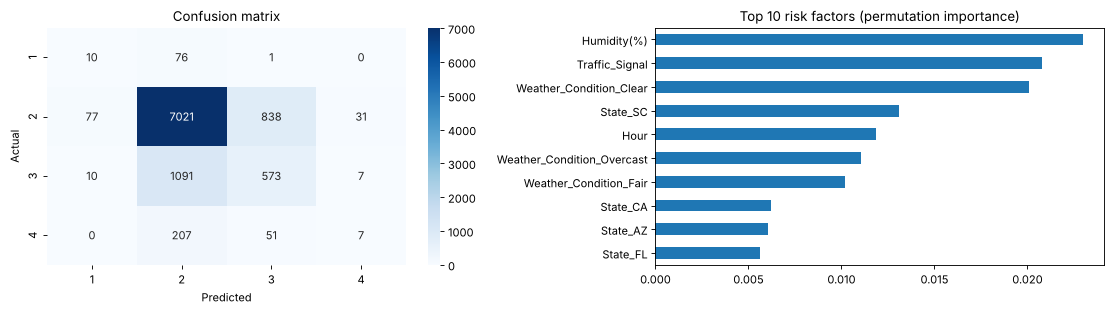

In [10]:
from sklearn.inspection import permutation_importance

pred = best.predict(X_test)
print(classification_report(y_te, pred, digits=2))

sub = X_test.sample(3000, random_state=1)
imp = permutation_importance(best, sub, y_te.loc[sub.index], scoring="f1_macro", n_repeats=3, random_state=42, n_jobs=-1)
top = pd.Series(imp.importances_mean, cols).nlargest(10)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(confusion_matrix(y_te, pred), annot=True, fmt="d", cmap="Blues", xticklabels=[1,2,3,4], yticklabels=[1,2,3,4], ax=ax[0])
ax[0].set_title("Confusion matrix"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")
top.sort_values().plot.barh(ax=ax[1], title="Top 10 risk factors (permutation importance)")
plt.tight_layout(); plt.show()

**Honest reading:** Severity 2 and 3 are predicted reasonably; Severity 1 and 4 are weak because they are rare and the inputs (weather, time, road features) cannot fully explain how serious a crash was. Importances show what the model uses, not what causes accidents.

## Step 9 - Save the model and test it like the app does
`main.py` loads this file with `model, cols = joblib.load(...)`.

In [11]:
joblib.dump((best, cols), "severity_model.pkl")
print("Model saved as severity_model.pkl")

# one new accident, built exactly the way main.py builds it
new = pd.DataFrame([{"Hour": 23, "DayOfWeek": 5, "Temperature(F)": 60, "Humidity(%)": 70, "Visibility(mi)": 10,
                     "Wind_Speed(mph)": 0, "Precipitation(in)": 0, "Junction": 0, "Traffic_Signal": 0, "Crossing": 0,
                     "Stop": 0, "Railway": 0, "Is_Night": 1, "Weather_Condition": "Fog", "State": "CA"}])
model, saved_cols = joblib.load("severity_model.pkl")
p = model.predict_proba(F.prepare(new, {}, F.known(saved_cols, "Weather_Condition_"), F.known(saved_cols, "State_"), saved_cols))[0]
print("Probabilities by severity:", {int(c): round(float(v), 2) for c, v in zip(model.classes_, p)})
print("Predicted severity:", int(model.classes_[p.argmax()]))

Model saved as severity_model.pkl
Probabilities by severity: {1: 0.12, 2: 0.68, 3: 0.18, 4: 0.02}
Predicted severity: 2
